# Introducing Pandas Objects

At the very basic level, Pandas objects can be thought of as **enhanced versions of NumPy structured arrays in which the rows and columns are identified with labels rather than simple integer indices.**
As we will see during the course of this chapter, Pandas provides a host of useful tools, methods, and functionality on top of the basic data structures, but **nearly everything that follows will require an understanding of what these structures are**.
Thus, before we go any further, let's introduce these three fundamental Pandas data structures: the ``Series``, ``DataFrame``, and ``Index``.

We will start our code sessions with the standard NumPy and Pandas imports:

In [1]:
import numpy as np
import pandas as pd

In [2]:
%pip install pandas

  Using cached pandas-3.0.6-cp312-cp312-win_amd64.whl.metadata (19 kB)
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.7 MB 4.2 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.7 MB 4.9 MB/s eta 0:00:02
   --------- ------------------------------ 2.4/9.7 MB 4.2 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.7 MB 4.1 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.7 MB 3.8 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.7 MB 3.9 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.7 MB 4.0 MB/s eta 0:00:01
   ---------------------------- ----------- 6.8/9.7 MB 4.2 MB/s eta 0:00:01
   -------------------------------- ------- 7.9/9.7 MB 4.2 MB/s eta 0:00:01
   ------------------------------------ --- 8.9/9.7 MB 4.3 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 4.2 MB/s eta 0:00:00
Note: you may need to re


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## The Pandas Series Object

A Pandas ``Series`` is a one-dimensional array of indexed data.
It can be created from a list or array as follows:

In [3]:
# Heights of class
import pandas as pd
data = pd.Series([1.5, 1.6, 1.75, 1.8,"hola"])
type(data[4])

str

In [8]:
data[0]+data[1]

3.1

In [ ]:
type

In [2]:
pd.__version__

'3.0.6'

In [3]:
pd.options.mode.copy_on_write=True

C:\tmp\ipykernel_26792\3002446623.py:1: Pandas4Warning: The 'mode.copy_on_write' option is deprecated. Copy-on-Write can no longer be disabled (it is always enabled with pandas >= 3.0), and setting the option has no impact. This option will be removed in pandas 4.0.
  pd.options.mode.copy_on_write=True


In [ ]:
data.values # así se ve el numpy que hay dentro

In [ ]:
data.values

In [9]:
data[4]=np.nan

As we see in the output, the ``Series`` wraps both a sequence of values and a sequence of indices, which we can access with the ``values`` and ``index`` attributes.
The ``values`` are simply a familiar NumPy array:

In [10]:
data = pd.Series([1.5, 1.6, 1.75, 1.8, "hola"])
data

0     1.5
1     1.6
2    1.75
3     1.8
4    hola
dtype: object

In [11]:
data[0] + data[1]

3.1

In [12]:
data.values

array([1.5, 1.6, 1.75, 1.8, 'hola'], dtype=object)

The ``index`` is an array-like object of type ``pd.Index``, which we'll discuss in more detail momentarily.

In [13]:
type(data)

pandas.Series

In [14]:
data.index

RangeIndex(start=0, stop=5, step=1)

Like with a NumPy array, data can be accessed by the associated index via the familiar Python square-bracket notation:

In [15]:
data[0]

1.5

In [16]:
#type(data.values[0])

In [17]:
data[1:3]

1     1.6
2    1.75
dtype: object

In [18]:
data[-1::-1]#[0]

4    hola
3     1.8
2    1.75
1     1.6
0     1.5
dtype: object

As we will see, though, **the Pandas ``Series`` is much more general and flexible than the one-dimensional NumPy** array that it emulates.

### ``Series`` as generalized NumPy array

From what we've seen so far, it may look like the ``Series`` object is basically interchangeable with a one-dimensional NumPy array.
**The essential difference is the presence of the index**: while the Numpy Array has an *implicitly defined* integer index used to access the values, the Pandas ``Series`` has an ***explicitly defined*** index associated with the values.

This explicit index definition gives the ``Series`` object additional capabilities. For example, the index need not be an integer, but can consist of values of any desired type.
For example, **if we wish, we can use strings as an index:**

In [5]:
data = pd.Series(data=[1.5, 1.6, 1.75, 1.80,1.6], 
                 index=['Jane', 'Joe', 'Susan', 'Mike','Rodrigo'])
data

Jane       1.50
Joe        1.60
Susan      1.75
Mike       1.80
Rodrigo    1.60
dtype: float64

In [6]:
data['Jane']

np.float64(1.5)

In [7]:
data.index

Index(['Jane', 'Joe', 'Susan', 'Mike', 'Rodrigo'], dtype='str')

In [8]:
data['Jane'].iloc()

AttributeError: 'numpy.float64' object has no attribute 'iloc'

In [23]:
data["Joe":"Mike"]

Joe      1.60
Susan    1.75
Mike     1.80
dtype: float64

In [25]:
data["Joe":"Mike":-1]

Series([], dtype: float64)

In [24]:
data["Mike":"Joe"]

Series([], dtype: float64)

In [12]:
data[-1::-1]


Rodrigo    1.60
Mike       1.80
Susan      1.75
Joe        1.60
Jane       1.50
dtype: float64

In [13]:
data[-1:0:-1]

Rodrigo    1.60
Mike       1.80
Susan      1.75
Joe        1.60
dtype: float64

In [14]:
test = pd.Series([1,2,3,4,5,6], index = ["Alberto", "Joe", "Mary", "Joe", "Peter", "Joe"])
test

Alberto    1
Joe        2
Mary       3
Joe        4
Peter      5
Joe        6
dtype: int64

In [11]:
test["Alberto":"Joe"] # no puedes hacer slicing para índices no únicos
test["Joe"]

KeyError: "Cannot get right slice bound for non-unique label: 'Joe'"

In [ ]:
data[1:3]

In [30]:
data['Susan']

print(data['Susan'])
print(data.iloc[2])
print(data.iloc[0:2])
print(data['Jane':'Susan'])

1.75
1.75
Jane    1.5
Joe     1.6
dtype: float64
Jane     1.50
Joe      1.60
Susan    1.75
dtype: float64


And the item access works as expected:

In [ ]:
data['Susan']

print(data['Susan'])
print(data.iloc[2])
print(data.iloc[0:2])
print(data['Jane':'Susan'])

We can even use non-contiguous or non-sequential indices:

In [ ]:
data = pd.Series([1.5, 1.6, 1.75, 1.80],
                 index=[2, 5, 3, 7])
data

In [ ]:
data[2:5]

### Series as specialized dictionary

In this way, you can think of a **Pandas ``Series`` a bit like a specialization of a Python dictionary.**
A dictionary is a structure that maps arbitrary keys to a set of arbitrary values, and a ``Series`` is a structure which maps typed keys to a set of typed values.
This typing is important: just as the type-specific compiled code behind a NumPy array makes it more efficient than a Python list for certain operations, the type information of a Pandas ``Series`` makes it much more efficient than Python dictionaries for certain operations.

The ``Series``-as-dictionary analogy can be made even more clear by constructing a ``Series`` object directly from a Python dictionary:

In [11]:
population_dict = {'California': 38332521,
                   'Texas': 26448193,
                   'New York': 19651127,
                   'Florida': 19552860,
                   'Illinois': 12882135}
population = pd.Series(population_dict)
population

California    38332521
Texas         26448193
New York      19651127
Florida       19552860
Illinois      12882135
dtype: int64

By default, a ``Series`` will be created where the index is drawn from the sorted keys.
From here, typical dictionary-style item access can be performed:

In [32]:
population['California']

np.int64(38332521)

Unlike a dictionary, though, the ``Series`` also supports array-style operations such as slicing:

In [33]:
population['California':'Illinois']

California    38332521
Texas         26448193
New York      19651127
Florida       19552860
Illinois      12882135
dtype: int64

We'll discuss some of the quirks of Pandas indexing and slicing in [Data Indexing and Selection](03.02-Data-Indexing-and-Selection.ipynb).

### Constructing Series objects

We've already seen a few ways of constructing a Pandas ``Series`` from scratch; all of them are some version of the following:

```python
>>> pd.Series(data, index=index)
```

where ``index`` is an optional argument, and ``data`` can be one of many entities.

For example, ``data`` can be a list or NumPy array, in which case ``index`` defaults to an integer sequence:

In [34]:
pd.Series([2,3,6])

0    2
1    3
2    6
dtype: int64

``data`` can be a scalar, which is repeated to fill the specified index:

In [35]:
pd.Series(5, index=[100, 200, 300])

100    5
200    5
300    5
dtype: int64

In [37]:
pd.Series(np.nan,index=[f"row{x}"for x in range(10000)])

row0      NaN
row1      NaN
row2      NaN
row3      NaN
row4      NaN
           ..
row9995   NaN
row9996   NaN
row9997   NaN
row9998   NaN
row9999   NaN
Length: 10000, dtype: float64

``data`` can be a dictionary, in which ``index`` defaults to the sorted dictionary keys:

In [38]:
pd.Series({2:'a', 1:'b', 3:'c'})

2    a
1    b
3    c
dtype: str

In each case, the index can be explicitly set if a different result is preferred:

In [39]:
p = pd.Series({2:'a', 1:'b', 3:'c'}, index=[3, 2])
p

3    c
2    a
dtype: str

In [40]:
p = pd.Series({2:'a', 1:'b', 3:'c'}, index=[3, 2,1])
p[0:2][2]

'a'

Notice that in this case, the ``Series`` is populated only with the explicitly identified keys.

## The Pandas DataFrame Object

The next fundamental structure in Pandas is the ``DataFrame``.
Like the ``Series`` object discussed in the previous section, the ``DataFrame`` can be **thought of either as a generalization of a NumPy array, or as a specialization of a Python dictionary.**
We'll now take a look at each of these perspectives.

### DataFrame as a generalized NumPy array
If a ``Series`` is an analog of a one-dimensional array with flexible indices, a **``DataFrame`` is an analog of a two-dimensional array with both flexible row indices and flexible column names.**
Just as you might think of a two-dimensional array as an ordered sequence of aligned one-dimensional columns, you can think of a ``DataFrame`` as a sequence of aligned ``Series`` objects.
Here, by "aligned" we mean that **they share the same index.**

To demonstrate this, let's first construct a new ``Series`` listing the area of each of the five states discussed in the previous section:

In [15]:
area_dict = {'California': 423967, 'Texas': 695662, 'New York': 141297,
             'Florida': 170312, 'Illinois': 149995}
area = pd.Series(area_dict)
area

California    423967
Texas         695662
New York      141297
Florida       170312
Illinois      149995
dtype: int64

Now that we have this along with the ``population`` Series from before, we can use a dictionary to construct a single two-dimensional object containing this information:

In [16]:
states = pd.DataFrame({'population': population,
                       'area': area})
states

,population,area
California,38332521,423967
Texas,26448193,695662
New York,19651127,141297
Florida,19552860,170312
Illinois,12882135,149995


In [43]:
type(states)

pandas.DataFrame

In [44]:
states.values

array([[38332521,   423967],
       [26448193,   695662],
       [19651127,   141297],
       [19552860,   170312],
       [12882135,   149995]])

Like the ``Series`` object, the ``DataFrame`` has an ``index`` attribute that gives access to the index labels:

In [45]:
states.index

Index(['California', 'Texas', 'New York', 'Florida', 'Illinois'], dtype='str')

Additionally, the ``DataFrame`` has a ``columns`` attribute, which is an ``Index`` object holding the column labels:

In [46]:
states.columns[:1]

Index(['population'], dtype='str')

In [47]:
states.columns

Index(['population', 'area'], dtype='str')

<Axes: >

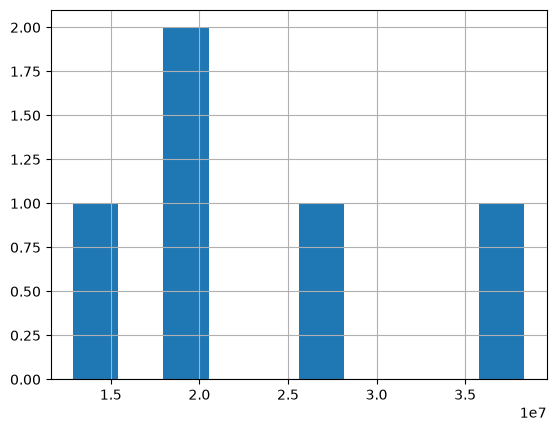

In [49]:
states["population"].hist()

In [52]:
states.head(3)
states.tail()
states.sample()

,population,area
Illinois,12882135,149995


In [53]:
states=states.sample(len(states))

In [56]:
midf=pd.DataFrame()
midf

""


In [3]:
import numpy as np
import pandas as pd
midf = pd.DataFrame()
midf['temperatura'] = [1,2,3]
midf

,temperatura
0,1
1,2
2,3


In [4]:
midf['temperatura_mayor_cero']=midf['temperatura']>0

In [5]:
midf

,temperatura,temperatura_mayor_cero
0,1,True
1,2,True
2,3,True


In [6]:
midf.temperatura +10

0    11
1    12
2    13
Name: temperatura, dtype: int64

**Thus the ``DataFrame`` can be thought of as a generalization of a two-dimensional NumPy array, where both the rows and columns have a generalized index for accessing the data.**

### DataFrame as specialized dictionary

Similarly, we can also think of a ``DataFrame`` as a specialization of a dictionary.
Where a dictionary maps a key to a value, a ``DataFrame`` maps a column name to a ``Series`` of column data.
For example, asking for the ``'area'`` attribute returns the ``Series`` object containing the areas we saw earlier:

In [17]:
states['population'].California

np.int64(38332521)

In [18]:
states['area'].name

'area'

In [21]:
states['area'].values.tolist()
states['area'].to_dict()

{'California': 423967,
 'Texas': 695662,
 'New York': 141297,
 'Florida': 170312,
 'Illinois': 149995}

In [ ]:
states.to_dict(orient)

**Notice the potential point of confusion here: in a two-dimesnional NumPy array, ``data[0]`` will return the first *row*. For a ``DataFrame``, ``data['col0']`` will return the first *column*.**
Because of this, it is probably better to think about ``DataFrame``s as generalized dictionaries rather than generalized arrays, though both ways of looking at the situation can be useful.
We'll explore more flexible means of indexing ``DataFrame``s in [Data Indexing and Selection](03.02-Data-Indexing-and-Selection.ipynb).

### Constructing DataFrame objects

A Pandas ``DataFrame`` can be constructed in a variety of ways.
Here we'll give several examples.

#### From a single Series object

A ``DataFrame`` is a collection of ``Series`` objects, and a single-column ``DataFrame`` can be constructed from a single ``Series``:

In [ ]:
pd.DataFrame(population, columns=['population'])


In [ ]:
pd.DataFrame(population, columns=['population'])['population']

In [ ]:
states.area

#### From a list of dicts

Any list of dictionaries can be made into a ``DataFrame``.
We'll use a simple list comprehension to create some data:

In [ ]:
data = [{'a': i, 'b': 2 * i} for i in range(3)]
pd.DataFrame(data)
# [{'a':0, 'b':0}, {'a':1, 'b':2}, {'a':2, 'b':4}]

In [ ]:
{  x : x*2   for x   in [1,2,3]   }

In [ ]:
[    x*2  if x ==2 or x == 1 else 10  for x  in [1,2,3]    ]  # list comprehension

In [ ]:
l = []
for x in [1,2,3]:
    l.append(x*2)
l

In [ ]:
[   x+1  for x in [1,2,3,9] ]

In [ ]:
{x: "letra: " + x for x in ['a','b','c']} # dict comprehesion

Even if some keys in the dictionary are missing, Pandas will fill them in with ``NaN`` (i.e., "not a number") values:

In [22]:
import pandas as pd
import numpy as np

midic1 = {'a': 1, 'b': 2}
midic2 = {'b': 3, 'c': 4}

midf = pd.DataFrame(data = [midic1, midic2])

midf = pd.DataFrame( data = [midic1, midic2])
midf.index = ["hola", "adiós"]
midf


,a,b,c
hola,1.0,2,NaN
adiós,NaN,3,4.0


In [23]:
midf.loc[:,midf.dtypes=="O"]

""
hola
adiós


In [ ]:
pd.DataFrame([{'a': "hola", 'b': 2}, { 'a': 1, 'b': 3, 'c': 4}]).dtypes

In [ ]:
type(pd.DataFrame([{'a': "hola", 'b': 2},
                   { 'a': 1, 'b': 3, 'c': 4}])
     .values[1][0])

In [ ]:
pd.DataFrame([{'a': "hola", 'b': 2},
                   { 'a': 1, 'b': 3, 'c': 4}])\
     .values[0][1]

In [ ]:
"lalala\nlelele"
"""lalala\nlelele
lololo"""

In [ ]:
type(pd.DataFrame([{'a': "hola", 'b': 2},
                   { 'a': 1, 'b': 3, 'c': 4}]).values[1][0])

In [ ]:
np.array([5]).dtype

In [ ]:
type(np.array([5])[0])

In [ ]:
print(
 "hola\
 qué\
 tal" 
)

In [ ]:
# 1.8   1.80  1.8000000000000001
# 8   8.

In [ ]:
np.inf

In [ ]:
float('inf')

In [ ]:
np.nan

#### From a dictionary of Series objects

As we saw before, a ``DataFrame`` can be constructed from a dictionary of ``Series`` objects as well:

In [ ]:
pd.DataFrame({'population': population,
              'area': area})

#### From a two-dimensional NumPy array

Given a two-dimensional array of data, we can create a ``DataFrame`` with any specified column and index names.
If omitted, an integer index will be used for each:

In [ ]:
pd.DataFrame(np.random.rand(3, 2),
             columns=['foo', 'bar'],
             index=['a', 'b', 'c'])

#### From a NumPy structured array

We covered structured arrays in [Structured Data: NumPy's Structured Arrays](02.09-Structured-Data-NumPy.ipynb).
A Pandas ``DataFrame`` operates much like a structured array, and can be created directly from one:

In [ ]:
import numpy as np
A = np.zeros(3, dtype=[('A', 'i8'), ('B', 'f8'), ('C', 'f8')])
A

In [ ]:
pd.DataFrame(A)

## The Pandas Index Object

We have seen here that both the ``Series`` and ``DataFrame`` objects contain an explicit *index* that lets you reference and modify data.
This ``Index`` object is an interesting structure in itself, and **it can be thought of either as an *immutable array* or as an *ordered set* (technically a multi-set, as ``Index`` objects may contain repeated values).**
Those views have some interesting consequences in the operations available on ``Index`` objects.
As a simple example, let's construct an ``Index`` from a list of integers:

In [ ]:
ind = pd.Index([2, 3, 5, 7, 11])
ind

### Index as immutable array

The ``Index`` in many ways operates like an array.
For example, we can use standard Python indexing notation to retrieve values or slices:

In [ ]:
ind[1]

In [ ]:
ind[::2]

``Index`` objects also have many of the attributes familiar from NumPy arrays:

In [ ]:
print(ind.size, ind.shape, ind.ndim, ind.dtype)

One difference between ``Index`` objects and NumPy arrays is that indices are immutable–that is, they cannot be modified via the normal means:

In [ ]:
ind[1] = 0

**This immutability makes it safer to share indices between multiple ``DataFrame``s and arrays, without the potential for side effects from inadvertent index modification.**

### Index as ordered set

Pandas objects are designed to facilitate operations such as joins across datasets, which depend on many aspects of set arithmetic.
**The ``Index`` object follows many of the conventions used by Python's built-in ``set`` data structure, so that unions, intersections, differences, and other combinations can be computed in a familiar way:**

In [ ]:
indA = pd.Index([1, 3, 5, 7, 9])
indB = pd.Index([2, 3, 5, 7, 11])

In [ ]:
indA & indB  # intersection

In [ ]:
indA.intersection(indB)

In [ ]:
indA.intersection(indB)
indA.__and__(indB) # indA & indB

In [ ]:
indA | indB  # union

In [ ]:
testindA = pd.Index([1,2,3,3,3,3,3,3])
testindB = pd.Index([2,3,1,5, 5, 1])
testindA.union(testindB)

In [ ]:
indA ^ indB  # symmetric difference

These operations may also be accessed via object methods, for example ``indA.intersection(indB)``.